[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

配置门噪声与读出噪声，观察 Bell 测量分布和偶校验概率。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 含噪声模拟

## 1. 门噪声

In [1]:
from pyqpanda3.core import depolarizing_error, GateType, NoiseModel

# Add error to a specific gate type on specific qubits
error = depolarizing_error(0.01)
noise = NoiseModel()

### 1.1 特定比特上的特定门

In [2]:
noise.add_quantum_error(error, GateType.CNOT, [0, 1])

### 1.2 特定比特上的多个门

In [3]:
noise.add_quantum_error(error, [GateType.H, GateType.T], [0])

### 1.3 所有比特上的特定门

In [4]:
noise.add_all_qubit_quantum_error(error, GateType.CNOT)

### 1.4 所有比特上的多个门

In [5]:
noise.add_all_qubit_quantum_error(error, [GateType.H, GateType.CNOT])

## 2. 测量噪声

### 2.1 特定比特的测量噪声

In [6]:
noise.add_read_out_error([[0.95, 0.05], [0.05, 0.95]], 0)

### 2.2 所有比特的测量噪声

In [7]:
noise.add_all_qubit_read_out_error([[0.95, 0.05], [0.05, 0.95]])

## 示例

下方统计 Z 基测量得到的偶校验概率 $P(00)+P(11)$，它不能单独作为 Bell 态保真度。
例如 $|\Phi^+\rangle$ 和 $|\Phi^-\rangle$ 的偶校验概率都为 1，但它们相互正交；区分相位还需要其他测量基。

In [8]:
from pyqpanda3.core import H, CNOT, QProg, measure, CPUQVM, GateType
from pyqpanda3.core import depolarizing_error, NoiseModel

In [9]:
prog = QProg()
prog << H(0) << CNOT(0, 1)
prog << measure([0, 1], [0, 1])

┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1

In [10]:
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(0.01), GateType.CNOT
)

In [11]:
machine = CPUQVM()
machine.run(prog, shots=100000, model=noise_model)

In [12]:
counts = machine.result().get_counts()
print(counts)
total = sum(counts.values())
p00 = counts.get('00', 0) / total
p11 = counts.get('11', 0) / total
print(f"P(00)={p00:.4f}  P(11)={p11:.4f}")
print(f"Even-parity probability (100k shots): {p00 + p11:.4f}")

{'00': 49457, '11': 49542, '01': 476, '10': 525}
P(00)=0.4946  P(11)=0.4954
Even-parity probability (100k shots): 0.9900


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

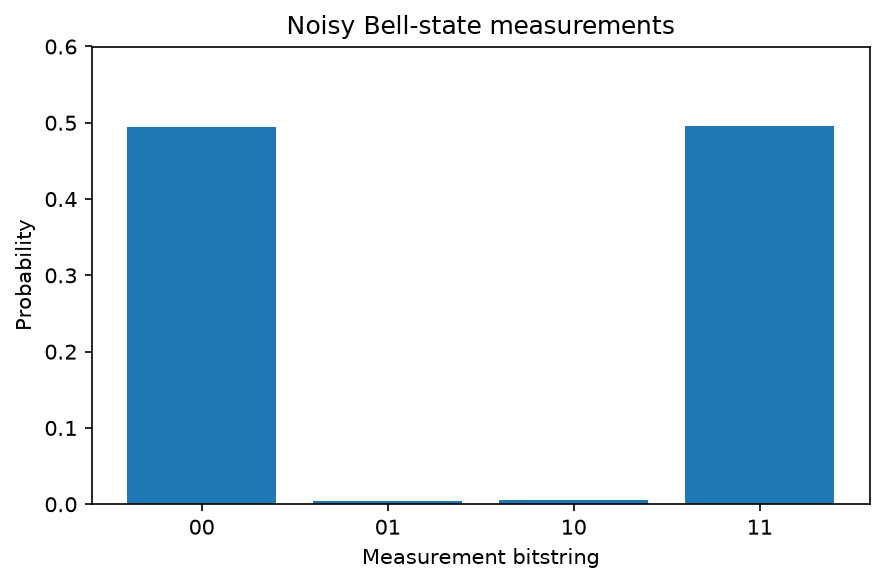

In [13]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

states = ["00", "01", "10", "11"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(states, [counts.get(state, 0) / total for state in states])
ax.set(xlabel="Measurement bitstring", ylabel="Probability", ylim=(0, 0.6), title="Noisy Bell-state measurements")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))
